# ML Zoomcamp 2026 — Homework 4: Evaluation Metrics for Classification
Lead-scoring dataset (2026 release). Target: `converted`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data preparation

In [2]:
print(df.isnull().sum())

categorical = list(df.select_dtypes(include=['object', 'string']).columns)
numerical = [c for c in df.columns if c not in categorical and c != 'converted']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train.converted.values
y_val = df_val.converted.values
len(df_train), len(df_val), len(df_test)

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


(3000, 1000, 1000)

## Question 1: ROC AUC feature importance

In [3]:
for c in ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print(f'{c:30s} {auc:.3f}')

lead_score                     0.788
number_of_courses_viewed       0.723
interaction_count              0.765
annual_income                  0.608


**Answer Q1:** `lead_score` (0.788)

## Question 2: Training the model

In [4]:
features = categorical + numerical

def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
print(round(roc_auc_score(y_val, y_pred), 3))

0.732


**Answer Q2:** 0.732

## Question 3: Precision and Recall

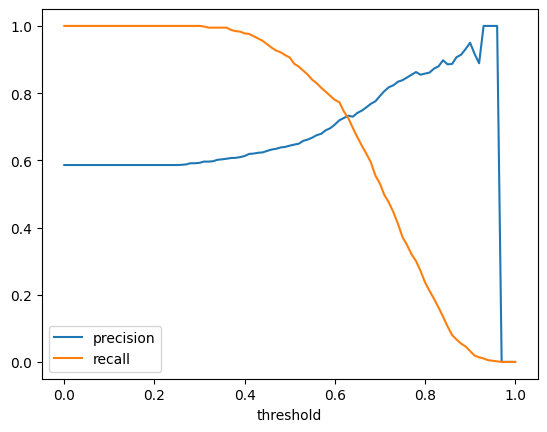

,threshold,precision,recall,f1,diff
63,0.63,0.732759,0.725256,0.728988,0.007503
62,0.62,0.725914,0.745734,0.735690,0.019820
64,0.64,0.729875,0.696246,0.712664,0.033629


In [5]:
rows = []
for t in np.arange(0.0, 1.01, 0.01):
    pred = y_pred >= t
    tp = ((pred) & (y_val == 1)).sum()
    fp = ((pred) & (y_val == 0)).sum()
    fn = ((~pred) & (y_val == 1)).sum()
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) else 0.0
    rows.append((round(t, 2), p, r, f1))

scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])

plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.show()

nz = scores[(scores.precision > 0) | (scores.recall > 0)].copy()
nz['diff'] = (nz.precision - nz.recall).abs()
nz.sort_values('diff').head(3)

**Answer Q3:** 0.63

## Question 4: F1 score

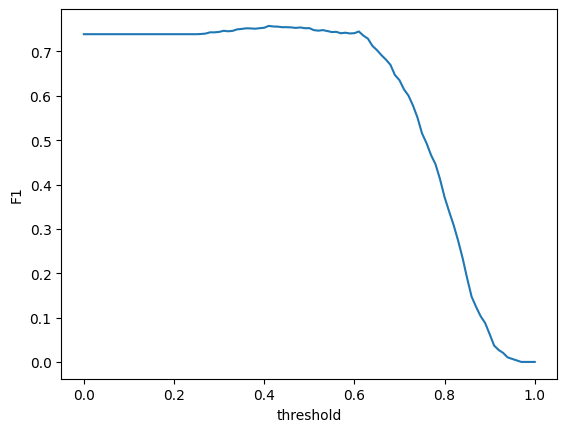

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032


In [6]:
plt.plot(scores.threshold, scores.f1)
plt.xlabel('threshold'); plt.ylabel('F1'); plt.show()
scores.sort_values('f1', ascending=False).head(3)

**Answer Q4:** 0.41

## Question 5: 5-Fold CV

In [7]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

def cv_scores(C=1.0):
    out = []
    for tr_idx, va_idx in kfold.split(df_full_train):
        d_tr = df_full_train.iloc[tr_idx]
        d_va = df_full_train.iloc[va_idx]
        dv_, m_ = train(d_tr, d_tr.converted.values, C=C)
        out.append(roc_auc_score(d_va.converted.values, predict(d_va, dv_, m_)))
    return np.array(out)

s = cv_scores()
print(s.round(4))
print('std:', round(s.std(), 3))

[0.7306 0.7296 0.7363 0.7412 0.7209]
std: 0.007


**Answer Q5:** 0.007

## Question 6: Hyperparameter tuning

In [8]:
for C in [0.000001, 0.001, 1]:
    s = cv_scores(C)
    print(f'C={C:<10} mean={s.mean():.3f} std={s.std():.3f}')

C=1e-06      mean=0.617 std=0.019


C=0.001      mean=0.749 std=0.010


C=1          mean=0.732 std=0.007


**Answer Q6:** C = 0.001